<a href="https://colab.research.google.com/github/CaptainREX4/Uczenie-maszynowe-2026/blob/main/01_lifesat.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**ML Lab 1**
<table align="left">
  <td>
    <a href="https://colab.research.google.com/github/marcinsawinski/UEP_KIE_ML_CLASS/blob/main/01_lifesat.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>
  </td>
</table>

### Note! Check hints in [Cheatsheet](https://colab.research.google.com/github/marcinsawinski/UEP_KIE_ML_LAB_PROG/blob/main/00_cheatsheet.ipynb)

# Task 1-1.1
_Get data and visualize_
- Download lifesat data into pandas dataframe called lifesat available at "https://github.com/marcinsawinski/UEP_KIE_ML_CLASS/raw/main/datasets/lifesat/lifesat.csv"
- Visualize with scatter plot "GDP per capita (USD)" on x axis , "Life satisfaction" of y axis

_Type your code below_

           Country  GDP per capita (USD)  Life satisfaction
0           Russia          26456.387938                5.8
1           Greece          27287.083401                5.4
2           Turkey          28384.987785                5.5
3           Latvia          29932.493910                5.9
4          Hungary          31007.768407                5.6
5         Portugal          32181.154537                5.4
6           Poland          32238.157259                6.1
7          Estonia          35638.421351                5.7
8            Spain          36215.447591                6.3
9         Slovenia          36547.738956                5.9
10       Lithuania          36732.034744                5.9
11          Israel          38341.307570                7.2
12           Italy          38992.148381                6.0
13  United Kingdom          41627.129269                6.8
14          France          42025.617373                6.5
15     New Zealand          42404.393738

<Axes: xlabel='GDP per capita (USD)', ylabel='Life satisfaction'>

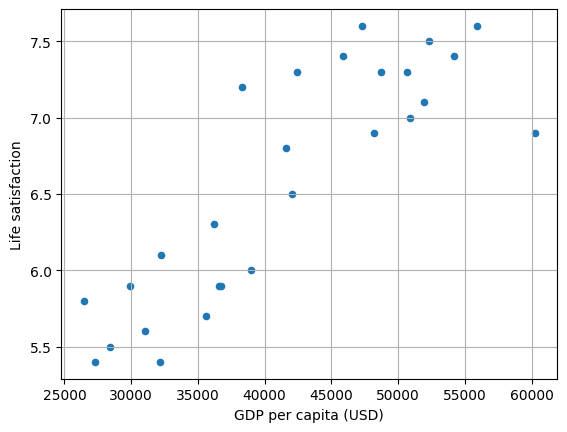

In [ ]:
import pandas as pd

# Download lifesat data into pandas dataframe called lifesat
url = "https://github.com/marcinsawinski/UEP_KIE_ML_CLASS/raw/main/datasets/lifesat/lifesat.csv"
lifesat = pd.read_csv(url)
print(lifesat)

# Visualize with scatter plot "GDP per capita (USD)" on x axis, "Life satisfaction" on y axis
lifesat.plot(kind='scatter', grid=True,
             x="GDP per capita (USD)", y="Life satisfaction")

# Task 1-1.2
_Train the model and predict_
- Assign new variable X with data from "GDP per capita (USD)" column converted to numpy array
- Assign new variable y with data from "Life satisfaction" column converted to numpy array
- Train linear regression Model for X and y and predict "Life satisfaction" when "GDP per capita (USD)" is equal 37655.2
- Train k-nearest neighbors Model with k=3 for X and y and predict "Life satisfaction" when "GDP per capita (USD)" is equal 37655.2
- Compare linear regression k-nearest neighbors results

_Type your code below_

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
import numpy as np

X = lifesat[['GDP per capita (USD)']].values
y = lifesat[['Life satisfaction']].values

lin_reg = LinearRegression()
lin_reg.fit(X, y)
X_New = np.array([[37655.2]])
lin_reg_pred = lin_reg.predict(X_New).round(4)[0][0]
print(lin_reg_pred)

knn_reg = KNeighborsRegressor(n_neighbors=3)
knn_reg.fit(X, y)
knn_reg_pred = knn_reg.predict(X_New).round(4)[0][0]
print(knn_reg_pred)


6.3017
6.3333


# Task 1-1.3
_Prepare dataset_
- Fetch Better Life Index (BLI) data from [OECD's website](http://stats.oecd.org/index.aspx?DataSetCode=BLI) (to get the Life Satisfaction for each country), and World Bank GDP per capita data from [OurWorldInData.org](https://ourworldindata.org/grapher/gdp-per-capita-worldbank)

files are copied here:

https://github.com/marcinsawinski/UEP_KIE_ML_CLASS/raw/main/datasets/lifesat/gdp-per-capita-worldbank.csv
https://github.com/marcinsawinski/UEP_KIE_ML_CLASS/raw/main/datasets/lifesat/oecd_bli_20221109.csv
- Preview fetched data
- Filter one 1 selected year
- Merge the life satisfaction data and the GDP per capita data, keeping only the GDP per capita and Life satisfaction columns
- Visuilza data on scatter plot
- Add linear regresion prediciton for countries with no Life satisfaction to the plot
- Add k-nearest neighbors prediciton for countries with no Life satisfaction to the plot

_Type your code below_

=== OECD BLI Preview ===


,LOCATION,Country,INDICATOR,Indicator,MEASURE,Measure,INEQUALITY,Inequality,Unit Code,Unit,PowerCode Code,PowerCode,Reference Period Code,Reference Period,Value,Flag Codes,Flags
0,AUS,Australia,JE_LMIS,Labour market insecurity,L,Value,TOT,Total,PC,Percentage,0,Units,NaN,NaN,3.1,NaN,NaN
1,AUT,Austria,JE_LMIS,Labour market insecurity,L,Value,TOT,Total,PC,Percentage,0,Units,NaN,NaN,2.3,NaN,NaN



=== World Bank GDP Preview ===


,Entity,Code,Year,"GDP per capita, PPP (constant 2017 international $)"
0,Afghanistan,AFG,2002,1189.784668
1,Afghanistan,AFG,2003,1235.810059


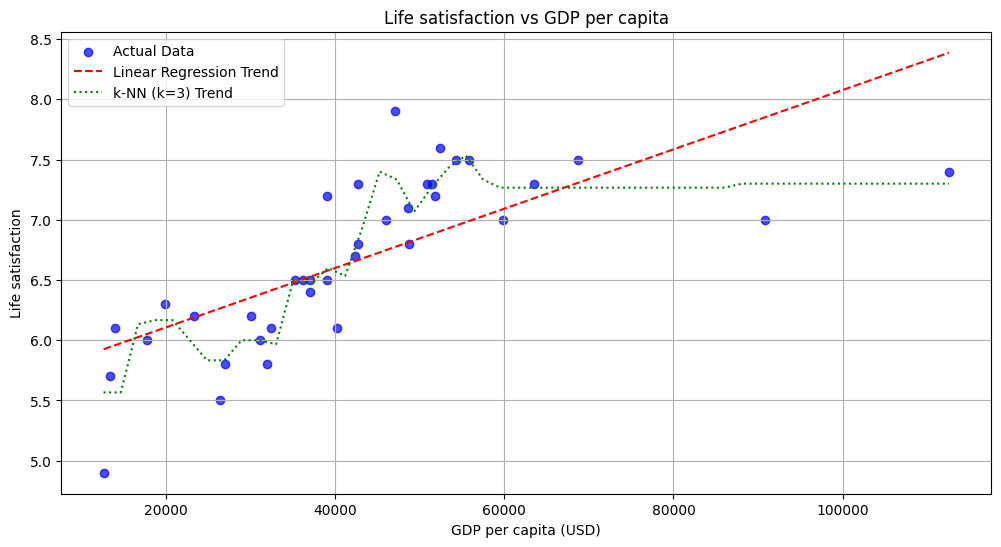

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor

# 1. Fetch data
url_worldbank = "https://github.com/marcinsawinski/UEP_KIE_ML_CLASS/raw/main/datasets/lifesat/gdp-per-capita-worldbank.csv"
url_oecd = "https://github.com/marcinsawinski/UEP_KIE_ML_CLASS/raw/main/datasets/lifesat/oecd_bli_20221109.csv"

df_wb = pd.read_csv(url_worldbank)
df_oecd = pd.read_csv(url_oecd)

# Preview data
print("=== OECD BLI Preview ===")
display(df_oecd.head(2))
print("\n=== World Bank GDP Preview ===")
display(df_wb.head(2))

# 2. Filter GDP data for year 2020
gdp_2020 = df_wb[df_wb["Year"] == 2020].copy()
gdp_2020.rename(columns={
    "Entity": "Country",
    "GDP per capita, PPP (constant 2017 international $)": "GDP per capita (USD)"
}, inplace=True)

# Filter OECD BLI data for Life satisfaction with Inequality == 'Total'
bli_ls = df_oecd[(df_oecd["Indicator"] == "Life satisfaction") & (df_oecd["Inequality"] == "Total")].copy()
bli_ls.rename(columns={"Value": "Life satisfaction"}, inplace=True)

# 3. Merge keeping only country, GDP, and Life satisfaction
merged = pd.merge(gdp_2020, bli_ls, on="Country", how="inner")
merged = merged[["Country", "GDP per capita (USD)", "Life satisfaction"]].dropna(subset=["GDP per capita (USD)"])

# Separate into countries with and without Life satisfaction
with_ls = merged.dropna(subset=["Life satisfaction"])
without_ls = merged[merged["Life satisfaction"].isna()].copy()

# 4. Train models on available data
X_train = with_ls[["GDP per capita (USD)"]].values
y_train = with_ls[["Life satisfaction"]].values

lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

knn_reg = KNeighborsRegressor(n_neighbors=3)
knn_reg.fit(X_train, y_train)

# Predict for missing countries if any
if not without_ls.empty:
    X_missing = without_ls[["GDP per capita (USD)"]].values
    without_ls["LS_pred_lin"] = lin_reg.predict(X_missing)
    without_ls["LS_pred_knn"] = knn_reg.predict(X_missing)

# 5. Visualize
plt.figure(figsize=(12, 6))
plt.scatter(with_ls["GDP per capita (USD)"], with_ls["Life satisfaction"], color="blue", label="Actual Data", alpha=0.7)

# Also create a dummy list of countries with missing Life satisfaction to predict for them on the plot
# We'll use a range of artificial GDP values for visualization representation of predictions if without_ls is empty
visual_gdp = np.linspace(merged["GDP per capita (USD)"].min(), merged["GDP per capita (USD)"].max(), 50).reshape(-1, 1)
plt.plot(visual_gdp, lin_reg.predict(visual_gdp), color="red", linestyle="--", label="Linear Regression Trend")
plt.plot(visual_gdp, knn_reg.predict(visual_gdp), color="green", linestyle=":", label="k-NN (k=3) Trend")

if not without_ls.empty:
    plt.scatter(without_ls["GDP per capita (USD)"], without_ls["LS_pred_lin"], color="red", marker="x", label="Predicted (Lin Reg)")
    plt.scatter(without_ls["GDP per capita (USD)"], without_ls["LS_pred_knn"], color="green", marker="o", facecolors="none", label="Predicted (k-NN)")

plt.xlabel("GDP per capita (USD)")
plt.ylabel("Life satisfaction")
plt.title("Life satisfaction vs GDP per capita")
plt.grid(True)
plt.legend()
plt.show()